# Tugas Topik-7: Seleksi Fitur
**Mata Kuliah Sains Data — Sistem Peringatan Dini Gejolak Harga Minyak Goreng di Indonesia**

Notebook ini melakukan seleksi fitur pada dataset tugas kelompok (harga mingguan minyak goreng nasional, PIHPS Bank Indonesia, 3 Jan 2022 – 24 Agu 2026) dengan tiga teknik: **Seleksi Univariate**, **Feature Importance (Random Forest)**, dan **Matriks Korelasi + Heatmap**.

**Target:** `Harga_MG` (harga mingguan *Minyak Goreng*, varian utama) → masalah **regresi**.

## 1. Import & Load Data
Dataset asli berformat *wide* (satu kolom per tanggal), sehingga ditransposisi menjadi satu baris per minggu.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder
from sklearn.feature_selection import (f_classif, f_regression,
                                       mutual_info_classif, mutual_info_regression)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import cross_val_score, KFold, TimeSeriesSplit

DATA_PATH, TARGET = "Tabel Harga Minyak Indonesia (2).xlsx", "Harga_MG"

raw = pd.read_excel(DATA_PATH)
harga = raw.drop(columns="No").set_index("Komoditas (Rp)").T
harga.index = pd.to_datetime(harga.index.str.replace(" ", ""), format="%d/%m/%Y")
harga = harga.apply(lambda c: pd.to_numeric(c.astype(str).str.replace(",", "").replace("-", np.nan)))
harga.columns = ["Harga_MG", "Harga_Curah", "Harga_Kemasan1", "Harga_Kemasan2"]
harga = harga.dropna()          # 2 minggu kosong (28 Feb 2022 & 2 Mei 2022) tidak diimputasi
print(harga.shape)
harga.info()

(241, 4)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 241 entries, 2022-01-03 to 2026-08-24
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Harga_MG        241 non-null    float64
 1   Harga_Curah     241 non-null    float64
 2   Harga_Kemasan1  241 non-null    float64
 3   Harga_Kemasan2  241 non-null    float64
dtypes: float64(4)
memory usage: 9.4 KB


## 2. Pembentukan Fitur
Data asli hanya berisi 4 kolom harga, sehingga fitur dibentuk dari data tersebut:
- **Harga varian lain** (`Harga_Curah`, `Harga_Kemasan1`, `Harga_Kemasan2`) pada minggu yang sama.
- **Fitur historis target** (hanya memakai data minggu sebelumnya, tanpa kebocoran): `Lag_1`, `Lag_2`, `Lag_4`, `Roll_Mean_4`, `Roll_Std_4`, `Pct_Change_1`.
- **Fitur waktu**: `Bulan`, `Minggu_ke`, `Tahun`.
- **Fitur hari besar keagamaan** (biner, bernilai 1 bila pekan tersebut beririsan dengan jendela hari besar): `Ramadan` (30 hari sebelum Idul Fitri), `Idul_Fitri` (±7 hari), `Idul_Adha` (−7..+3 hari), `Nyepi` (−3..+1 hari), `Natal` (−7..+3 hari).

In [2]:
fitri = ["2022-05-02", "2023-04-22", "2024-04-10", "2025-03-31", "2026-03-21"]
libur = {
    "Ramadan":    (fitri, -30, -1),
    "Idul_Fitri": (fitri, -7, 7),
    "Idul_Adha":  (["2022-07-09", "2023-06-29", "2024-06-17", "2025-06-06", "2026-05-27"], -7, 3),
    "Nyepi":      (["2022-03-03", "2023-03-22", "2024-03-11", "2025-03-29", "2026-03-19"], -3, 1),
    "Natal":      (["2022-12-25", "2023-12-25", "2024-12-25", "2025-12-25", "2026-12-25"], -7, 3),
}

s = harga[TARGET]
fitur = harga.drop(columns=TARGET).copy()
fitur["Lag_1"], fitur["Lag_2"], fitur["Lag_4"] = s.shift(1), s.shift(2), s.shift(4)
fitur["Roll_Mean_4"] = s.shift(1).rolling(4).mean()
fitur["Roll_Std_4"] = s.shift(1).rolling(4).std()
fitur["Pct_Change_1"] = s.shift(1).pct_change()
fitur["Bulan"] = fitur.index.month
fitur["Minggu_ke"] = fitur.index.isocalendar().week.astype(int)
fitur["Tahun"] = fitur.index.year

pekan_akhir = fitur.index + pd.Timedelta(days=6)
for nama, (tanggal, bawah, atas) in libur.items():
    fitur[nama] = 0
    for d in pd.to_datetime(tanggal):
        fitur[nama] |= ((fitur.index <= d + pd.Timedelta(days=atas)) &
                        (pekan_akhir >= d + pd.Timedelta(days=bawah))).astype(int)

df = fitur.assign(**{TARGET: s}).dropna()   # baris awal tanpa lag dibuang
print(df.shape)
df.head()

(237, 18)


,Harga_Curah,Harga_Kemasan1,Harga_Kemasan2,Lag_1,Lag_2,Lag_4,Roll_Mean_4,Roll_Std_4,Pct_Change_1,Bulan,Minggu_ke,Tahun,Ramadan,Idul_Fitri,Idul_Adha,Nyepi,Natal,Harga_MG
2022-01-31,18500.0,20500.0,19500.0,20250.0,20350.0,20000.0,20187.5,149.303941,-0.004914,1,5,2022,0,0,0,0,0,19700.0
2022-02-07,17850.0,19950.0,18750.0,19700.0,20250.0,20150.0,20112.5,286.865241,-0.027160,2,6,2022,0,0,0,0,0,19050.0
2022-02-14,17400.0,19650.0,18450.0,19050.0,19700.0,20350.0,19837.5,597.738795,-0.032995,2,7,2022,0,0,0,0,0,18700.0
2022-02-21,17250.0,19450.0,18300.0,18700.0,19050.0,20250.0,19425.0,688.597609,-0.018373,2,8,2022,0,0,0,0,0,18550.0
2022-03-07,17050.0,20100.0,19000.0,18550.0,18700.0,19700.0,19000.0,511.533642,-0.008021,3,10,2022,0,0,0,0,0,18900.0


## 3. Preprocessing Minimal

In [3]:
df = df.drop_duplicates()
y = df.pop(TARGET)
X = df.copy()

num = X.select_dtypes("number").columns
cat = X.columns.difference(num)
X[num] = X[num].fillna(X[num].median())
if len(cat):
    X[cat] = OrdinalEncoder().fit_transform(X[cat].fillna(X[cat].mode().iloc[0]))

is_clf = y.dtype == "object" or y.nunique() <= 10
y = LabelEncoder().fit_transform(y) if is_clf else y
display(Markdown(f"**Tipe task: {'Klasifikasi' if is_clf else 'Regresi'}** — {X.shape[0]} sampel, {X.shape[1]} fitur."))

**Tipe task: Regresi** — 237 sampel, 17 fitur.

## 4. Seleksi Univariate
Skor F (korelasi linear) dan *Mutual Information* (hubungan linear maupun non-linear) antara tiap fitur dan target.

In [4]:
score_fn, mi_fn = ((f_classif, mutual_info_classif) if is_clf
                   else (f_regression, mutual_info_regression))
uni = pd.DataFrame({"F_score": score_fn(X, y)[0],
                    "Mutual_Info": mi_fn(X, y, random_state=42)}, index=X.columns)
uni = uni.sort_values("F_score", ascending=False)
uni.round(3)

,F_score,Mutual_Info
Lag_1,6028.879,2.141
Harga_Kemasan2,3429.516,1.883
Lag_2,2212.435,1.859
Roll_Mean_4,1840.902,1.865
Harga_Kemasan1,1563.815,1.754
Lag_4,693.337,1.581
Harga_Curah,408.157,1.560
Roll_Std_4,43.384,0.479
Tahun,30.688,0.951
Pct_Change_1,9.476,0.217


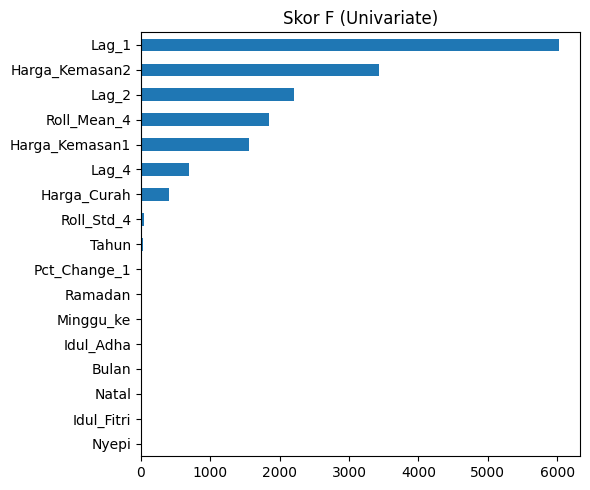

In [5]:
uni["F_score"].sort_values().plot.barh(figsize=(6, 5), title="Skor F (Univariate)")
plt.tight_layout();

## 5. Feature Importance (Random Forest)

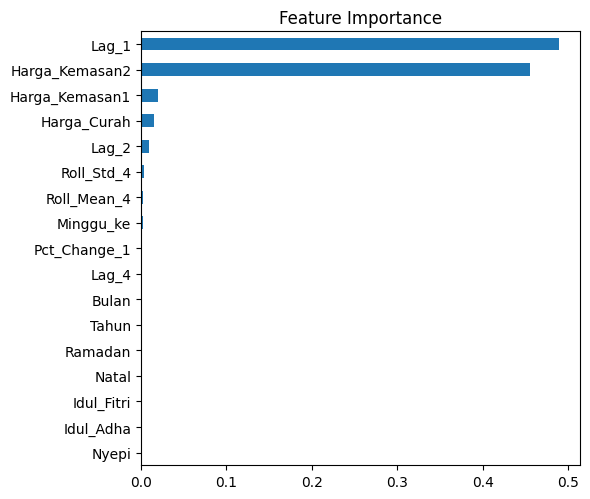

In [6]:
RF = RandomForestClassifier if is_clf else RandomForestRegressor
imp = pd.Series(RF(n_estimators=200, random_state=42).fit(X, y).feature_importances_,
                index=X.columns).sort_values()
imp.plot.barh(figsize=(6, max(3, len(imp) * 0.3)), title="Feature Importance")
plt.tight_layout();

## 6. Matriks Korelasi + Heatmap
Pasangan fitur dengan korelasi antar-fitur **> 0,8** dianggap redundan.

korelasi
Lag_2          Roll_Mean_4        0.993
Lag_1          Lag_2              0.981
Harga_Kemasan1 Harga_Kemasan2     0.980
Lag_1          Roll_Mean_4        0.976
Lag_4          Roll_Mean_4        0.975
Harga_Kemasan2 Lag_1              0.962
Lag_2          Lag_4              0.949
Bulan          Minggu_ke          0.947
Harga_Kemasan2 Lag_2              0.938
               Roll_Mean_4        0.931
Harga_Kemasan1 Lag_1              0.924
Lag_1          Lag_4              0.909
Harga_Kemasan1 Lag_2              0.906
               Roll_Mean_4        0.901
Harga_Kemasan2 Lag_4              0.862
Harga_Kemasan1 Lag_4              0.841

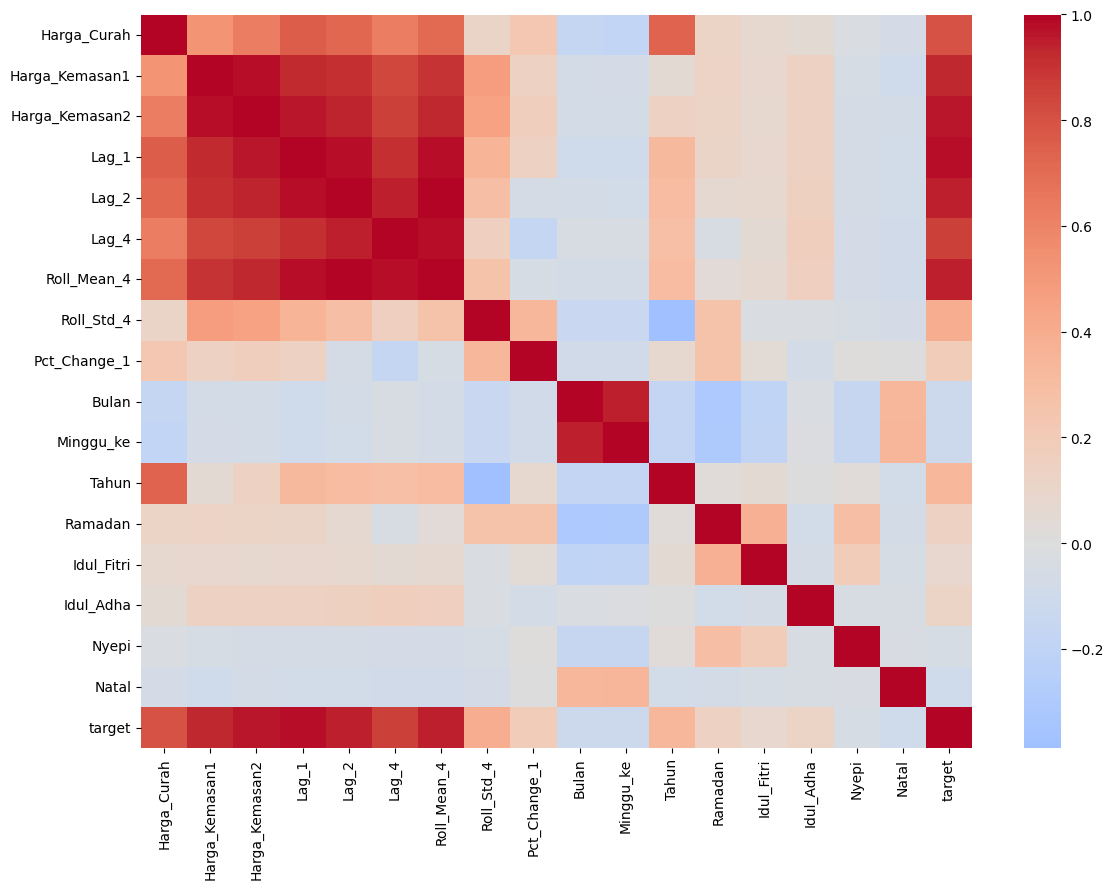

In [7]:
corr = X.assign(target=y).corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="coolwarm", center=0, annot=len(X.columns) <= 15, fmt=".2f")
plt.tight_layout()

fc = X.corr().abs()
upper = fc.where(np.triu(np.ones(fc.shape, bool), k=1))
pasangan = upper.stack().loc[lambda v: v > 0.8].sort_values(ascending=False)
pasangan.rename("korelasi").round(3).to_frame()

## 7. Konsolidasi & Pemilihan Fitur
Peringkat dari tiga metode dirata-rata. Fitur dipilih berurutan dari peringkat terbaik; fitur yang berkorelasi > 0,8 dengan fitur yang **sudah terpilih** dibuang, sehingga dari tiap kelompok redundan yang dipertahankan adalah fitur dengan peringkat terbaik. Kemudian diambil top-K, dengan K = setengah jumlah fitur.

In [8]:
rank = pd.DataFrame({"F": uni.F_score, "MI": uni.Mutual_Info, "RF": imp}).rank(ascending=False)
rank["avg_rank"] = rank.mean(axis=1)
rank = rank.sort_values("avg_rank")

tersisa = []
for c in rank.index:
    if all(fc.loc[c, t] <= 0.8 for t in tersisa):
        tersisa.append(c)
redundant = [c for c in rank.index if c not in tersisa]

K = max(3, len(X.columns) // 2)
selected = tersisa[:K]
print("Redundan dibuang:", redundant)
rank.loc[selected]

Redundan dibuang: ['Harga_Kemasan2', 'Lag_2', 'Harga_Kemasan1', 'Roll_Mean_4', 'Lag_4', 'Bulan']


,F,MI,RF,avg_rank
Lag_1,1.0,1.0,1.0,1.000000
Harga_Curah,7.0,7.0,4.0,6.000000
Roll_Std_4,8.0,10.0,6.0,8.000000
Tahun,9.0,8.0,12.0,9.666667
Pct_Change_1,10.0,12.0,9.0,10.333333
Minggu_ke,12.0,11.0,8.0,10.333333
Ramadan,11.0,13.0,13.0,12.333333
Idul_Adha,13.0,14.0,16.0,14.333333


## 8. Validasi Singkat (sebelum vs sesudah)
Skor R² Random Forest dengan 5-fold. Karena data berupa deret waktu, `KFold` acak dilengkapi `TimeSeriesSplit` yang menjaga urutan waktu.

In [9]:
est, metric = (RF(random_state=42), "accuracy" if is_clf else "r2")
cvs = {"KFold acak": KFold(5, shuffle=True, random_state=42),
       "TimeSeriesSplit": TimeSeriesSplit(5)}
pd.DataFrame({cv_name: {name: cross_val_score(est, X[cols], y, cv=cv, scoring=metric).mean()
                        for name, cols in {"Semua fitur": X.columns, "Terseleksi": selected}.items()}
              for cv_name, cv in cvs.items()}).round(4)

,KFold acak,TimeSeriesSplit
Semua fitur,0.9676,-7.1755
Terseleksi,0.9655,-6.6927


## 9. Simpan Dataset Terseleksi

In [10]:
X[selected].assign(**{TARGET: y}).to_csv("dataset_terseleksi.csv", index=False)

## 10. Analisis Hasil Seleksi Fitur

**Fitur paling berpengaruh.** Ketiga metode sepakat bahwa `Lag_1` (harga minggu sebelumnya) adalah fitur terkuat: peringkat 1 pada skor F (6.028,9), *Mutual Information* (2,141), maupun *feature importance* Random Forest (0,489). Di posisi kedua ketiganya juga sepakat pada `Harga_Kemasan2` (F = 3.429,5; MI = 1,883; RF = 0,455). Ini wajar karena harga minyak goreng sangat persisten dari minggu ke minggu dan harga antar-varian bergerak searah. Perbedaan muncul pada fitur lain: korelasi linear (F) menilai `Lag_2`, `Roll_Mean_4` dan `Harga_Kemasan1` tinggi, tetapi Random Forest memberi bobot hampir nol (< 0,02) karena informasinya sudah "diambil" oleh `Lag_1` dan `Harga_Kemasan2` (efek fitur berkorelasi). Sebaliknya, fitur hari besar keagamaan (`Ramadan`, `Idul_Adha`, `Natal`, `Idul_Fitri`, `Nyepi`) berada di peringkat bawah pada semua metode (F < 5, MI ≤ 0,127, RF ≈ 0). Menurut saya ini bukan berarti hari besar tidak berpengaruh, melainkan efeknya relatif kecil dibanding level harga yang didominasi tren dan inersia mingguan; pengaruh hari besar lebih tepat ditangkap sebagai efek tambahan terhadap perubahan harga (seperti pada model Prophet di proyek utama), bukan terhadap level harga.

**Fitur redundan.** Dengan ambang korelasi > 0,8 terdapat 16 pasangan fitur redundan, misalnya `Lag_2`–`Roll_Mean_4` (0,993), `Lag_1`–`Lag_2` (0,981), `Harga_Kemasan1`–`Harga_Kemasan2` (0,980), `Lag_1`–`Roll_Mean_4` (0,976), `Harga_Kemasan2`–`Lag_1` (0,962) dan `Bulan`–`Minggu_ke` (0,947). Pada tiap kelompok yang saling berkorelasi, hanya fitur berperingkat terbaik yang dipertahankan, sehingga fitur yang dibuang adalah `Harga_Kemasan2`, `Harga_Kemasan1`, `Lag_2`, `Roll_Mean_4`, `Lag_4` dan `Bulan`. Fitur-fitur ini membawa informasi yang hampir sama dengan `Lag_1` (harga lampau/varian sejenis), sehingga mempertahankannya hanya menambah multikolinearitas tanpa informasi baru. Perlu dicatat, `Harga_Kemasan2` dibuang walaupun peringkatnya ke-2, karena berkorelasi 0,962 dengan `Lag_1` yang peringkatnya lebih baik.

**Fitur terpilih dan validasi.** Dengan K = 8 (setengah dari 17 fitur), fitur yang dipilih adalah `Lag_1`, `Harga_Curah`, `Roll_Std_4`, `Tahun`, `Pct_Change_1`, `Minggu_ke`, `Ramadan` dan `Idul_Adha`. Himpunan ini mewakili level harga (`Lag_1`), varian lain yang informasinya berbeda (`Harga_Curah`, korelasinya dengan fitur lain ≤ 0,8), volatilitas dan momentum jangka pendek (`Roll_Std_4`, `Pct_Change_1`), tren jangka panjang (`Tahun`), musiman (`Minggu_ke`), dan dua fitur hari besar keagamaan yang berperingkat tertinggi. Sebagian anggota (`Ramadan`, `Idul_Adha`) sebenarnya berperingkat rendah dan terpilih hanya karena kuota K; keduanya dipertahankan karena relevan dengan tujuan proyek. Dengan *KFold* acak, R² Random Forest nyaris tidak berubah: 0,9676 (17 fitur) menjadi 0,9655 (8 fitur), artinya jumlah fitur turun lebih dari separuh dengan kehilangan akurasi hanya ≈ 0,002. Dengan `TimeSeriesSplit`, R² sama-sama sangat negatif (−7,18 vs −6,69; sedikit lebih baik setelah seleksi). Hal ini disebabkan model berbasis pohon tidak bisa mengekstrapolasi level harga di luar rentang data latih (harga berubah rezim antar periode), sehingga angka ini lebih menggambarkan keterbatasan memprediksi level harga langsung daripada kualitas seleksi fitur; perbandingan sebelum–sesudah tetap menunjukkan bahwa seleksi tidak merugikan.

**Kesimpulan.** Harga minggu sebelumnya (`Lag_1`) adalah fitur paling informatif, banyak fitur harga lain bersifat redundan, dan 8 fitur terseleksi sudah cukup mempertahankan kinerja model (R² 0,9655 vs 0,9676) dengan dataset yang lebih ringkas.
